<a href="https://colab.research.google.com/github/tzallll/Quantum_Spin_Benchmarking/blob/main/model%3B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 91.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 110.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 77.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]

CONFIGURATION: 1
Processing n = 2
Processing n = 4
Processing n = 8
Configuration completed.

CONFIGURATION: 2
Processing n = 2
Processing n = 4
Processing n = 8
Configuration completed.

CONFIGURATION: 3
Processing n = 2
Processing n = 4
Processing n = 8
Configuration completed.

CONFIGURATION: 4
Processing n = 2
Processing n = 4
Processing n = 8
Configuration completed.

CONFIGURATION: 5
Processing n = 2
Processing n = 4
Processing n = 8
Configuration completed.

CONFIGURATION: 6
Processing n = 2
Processing n = 4
Processing n = 8
Configuration completed.

CONFIGURATION: 7
Processing n = 2
Processing n = 4
Processing n = 8
Configuration completed.

CONFIGURATION: 8
Processing n = 2
Processing n = 4
Proc

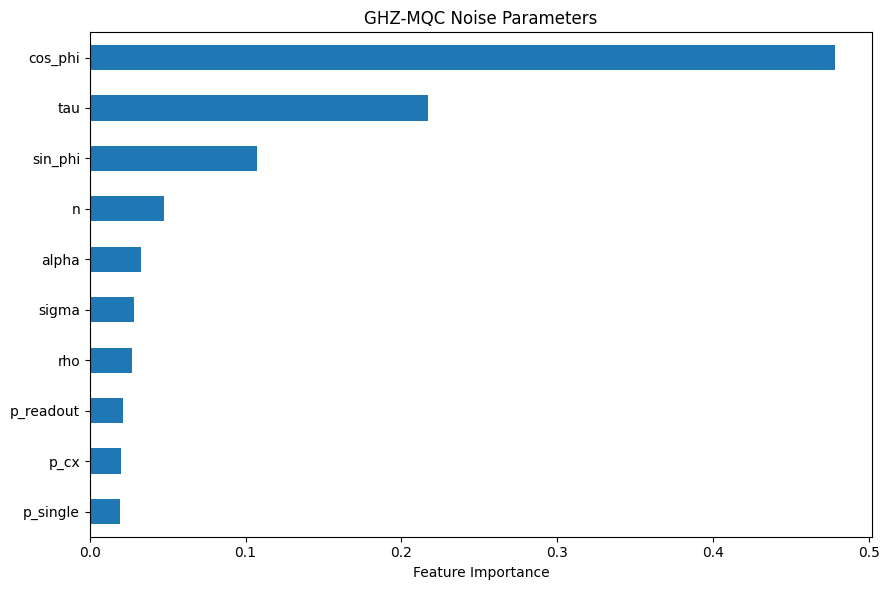

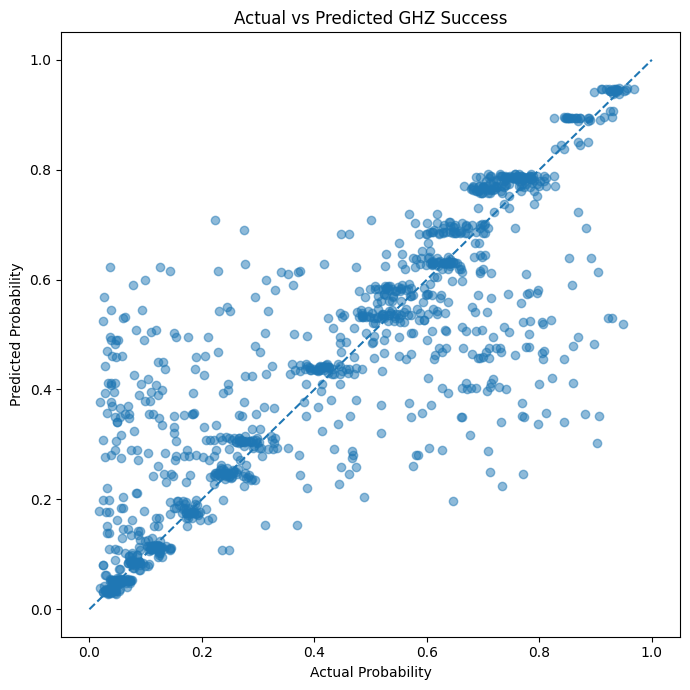


MODEL SAVED SUCCESSFULLY


In [2]:
!pip install qiskit qiskit-aer

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    depolarizing_error,
    ReadoutError
)

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# 1. GHZ MIRROR CIRCUIT
# ============================================================

def build_ghz_mirror(n, theta, phi, root_mode="middle"):

    qc = QuantumCircuit(n, n)

    if root_mode == "first":
        root = 0
    elif root_mode == "middle":
        root = n // 2
    else:
        raise ValueError("Invalid root_mode")

    cnot_list = []

    for q in range(root, n - 1):
        cnot_list.append((q, q + 1))

    for q in range(root, 0, -1):
        cnot_list.append((q, q - 1))

    qc.h(root)

    for ctrl, targ in cnot_list:
        qc.cx(ctrl, targ)

    for i in range(n):
        qc.rz(theta[i] + phi, i)

    for ctrl, targ in reversed(cnot_list):
        qc.cx(ctrl, targ)

    qc.h(root)

    qc.measure(range(n), range(n))

    return qc


# ============================================================
# 2. TIME-VARYING 1/f^alpha NOISE
# ============================================================

def sample_1f_noise(
    n,
    n_samples,
    sigma,
    rho,
    alpha,
    rng,
    trace_length=4096
):

    frequencies = np.fft.rfftfreq(trace_length)

    frequencies[0] = frequencies[1]

    noise_traces = np.zeros((trace_length, n))

    for q in range(n):

        white_noise = rng.normal(
            0, 1, trace_length
        )

        spectrum = np.fft.rfft(white_noise)

        # PSD proportional to 1/f^alpha

        spectrum /= frequencies ** (alpha / 2)

        spectrum[0] = 0

        signal = np.fft.irfft(
            spectrum,
            n=trace_length
        )

        signal /= np.std(signal)

        noise_traces[:, q] = sigma * signal

    # Spatial correlation

    indices = np.arange(n)

    distance = np.abs(
        indices[:, None] - indices[None, :]
    )

    correlation = rho ** distance

    L = np.linalg.cholesky(correlation)

    noise_traces = noise_traces @ L.T

    # Select different time points

    time_indices = np.linspace(
        0,
        trace_length - 1,
        n_samples,
        dtype=int
    )

    return noise_traces[time_indices]


# ============================================================
# 3. RANDOM AER NOISE MODEL
# ============================================================

def build_noise_model(
    p_cx,
    p_single,
    p_readout
):

    noise_model = NoiseModel()

    # Two-qubit depolarizing noise

    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(p_cx, 2),
        ["cx"]
    )

    # Single-qubit depolarizing noise

    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(p_single, 1),
        ["h", "rz"]
    )

    # Symmetric readout error

    readout = ReadoutError([
        [1 - p_readout, p_readout],
        [p_readout, 1 - p_readout]
    ])

    noise_model.add_all_qubit_readout_error(readout)

    return noise_model


# ============================================================
# 4. EXPERIMENT CONFIGURATION
# ============================================================

rng = np.random.default_rng(42)

# Qubit numbers

n_list = [2, 4, 8]

# Noise intensity scaling

tau_grid = np.concatenate((
    [0.0],
    np.logspace(-2, 1, 5)
))

# Number of different noise configurations

n_configs = 12

# Different temporal noise realizations
# for every configuration

n_realizations = 2

# Measurements per circuit

shots = 512

records = []


# ============================================================
# 5. DATASET GENERATION
# ============================================================

for config in range(n_configs):

    print("\nCONFIGURATION:", config + 1)

    # Random physical noise parameters

    sigma = rng.uniform(0.05, 0.5)

    rho = rng.uniform(0.0, 0.95)

    alpha = rng.uniform(0.5, 2.0)

    # Random Aer noise parameters

    p_cx = rng.uniform(1e-3, 1e-2)

    p_single = rng.uniform(1e-4, 1e-3)

    p_readout = rng.uniform(0.005, 0.03)

    # Create noise model

    noise_model = build_noise_model(
        p_cx,
        p_single,
        p_readout
    )

    simulator = AerSimulator(
        noise_model=noise_model
    )

    for n in n_list:

        print("Processing n =", n)

        phi_grid = [
            2 * np.pi * k / (2 * n + 1)
            for k in range(2 * n + 1)
        ]

        target = "0" * n

        # Generate noise realizations once.
        # Reuse each realization for all tau and phi.

        noise_traces = sample_1f_noise(
            n=n,
            n_samples=n_realizations,
            sigma=sigma,
            rho=rho,
            alpha=alpha,
            rng=rng
        )

        circuits = []
        metadata = []

        # Build all circuits before running them

        for realization in range(n_realizations):

            delta = noise_traces[realization]

            for tau in tau_grid:

                theta = tau * delta

                for phi in phi_grid:

                    qc = build_ghz_mirror(
                        n,
                        theta,
                        phi,
                        root_mode="middle"
                    )

                    circuits.append(qc)

                    metadata.append({
                        "config": config,
                        "realization": realization,
                        "n": n,
                        "tau": tau,
                        "phi": phi,
                        "sigma": sigma,
                        "rho": rho,
                        "alpha": alpha,
                        "p_cx": p_cx,
                        "p_single": p_single,
                        "p_readout": p_readout
                    })

        # Run the entire batch

        job = simulator.run(
            circuits,
            shots=shots
        )

        result = job.result()

        # Collect all measurements

        for i, info in enumerate(metadata):

            counts = result.get_counts(i)

            successes = counts.get(target, 0)

            probability = successes / shots

            row = info.copy()

            row["successes"] = successes
            row["shots"] = shots
            row["P_success"] = probability

            records.append(row)

    print("Configuration completed.")


# ============================================================
# 6. CREATE DATAFRAME
# ============================================================

df = pd.DataFrame(records)

# Periodic encoding of phi

df["sin_phi"] = np.sin(df["phi"])

df["cos_phi"] = np.cos(df["phi"])

# Save all raw data

df.to_csv(
    "GHZ_MQC_dataset.csv",
    index=False
)

print("\nDATASET CREATED")

print("Shape:", df.shape)

print(df.head())

print(df.describe())


# ============================================================
# 7. MACHINE LEARNING INPUTS
# ============================================================

features = [
    "n",
    "tau",
    "sin_phi",
    "cos_phi",
    "sigma",
    "rho",
    "alpha",
    "p_cx",
    "p_single",
    "p_readout"
]

X = df[features]

y = df["P_success"]

# Group by noise configuration.
# Entire configurations are held out from training.

groups = df["config"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]


# ============================================================
# 8. RANDOM FOREST REGRESSION
# ============================================================

model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)


# ============================================================
# 9. PREDICTIONS
# ============================================================

y_pred = model.predict(X_test)

# Keep predictions in probability range

y_pred = np.clip(y_pred, 0, 1)


# ============================================================
# 10. EVALUATION
# ============================================================

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(
    y_test,
    y_pred
)

print("\nMODEL RESULTS")

print("MAE:", mae)

print("RMSE:", rmse)

print("R2:", r2)


# ============================================================
# 11. FEATURE IMPORTANCE
# ============================================================

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values()

plt.figure(figsize=(9, 6))

importance.plot(kind="barh")

plt.xlabel("Feature Importance")

plt.title("GHZ-MQC Noise Parameters")

plt.tight_layout()

plt.savefig("feature_importance.png")

plt.show()


# ============================================================
# 12. ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Actual Probability")

plt.ylabel("Predicted Probability")

plt.title("Actual vs Predicted GHZ Success")

plt.tight_layout()

plt.savefig("actual_vs_predicted.png")

plt.show()


# ============================================================
# 13. SAVE TRAINED MODEL
# ============================================================

joblib.dump(
    model,
    "GHZ_MQC_RandomForest.pkl"
)

print("\nMODEL SAVED SUCCESSFULLY")